In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

plt.rcParams["figure.figsize"] = (8, 5)
print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
df_bc = pd.read_csv("breast-cancer.csv")
print("Shape:", df_bc.shape)
print("\nFirst 5 rows:")
df_bc.head()

Shape: (569, 32)

First 5 rows:


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [ ]:
print("Class distribution:")
print(df_bc["diagnosis"].value_counts())
print("\nMissing values:", df_bc.isnull().sum().sum())

Class distribution:
diagnosis
B    357
M    212
Name: count, dtype: int64

Missing values: 0


In [ ]:
# Encode target: M=1 (Malignant), B=0 (Benign)
le = LabelEncoder()
df_bc["target"] = le.fit_transform(df_bc["diagnosis"])  # B=0, M=1

X_bc = df_bc.drop(columns=["diagnosis", "target"])
y_bc = df_bc["target"]

X_train_bc, X_test_bc, y_train_bc, y_test_bc = train_test_split(
    X_bc, y_bc, test_size=0.2, random_state=42
)

scaler_bc = StandardScaler()
X_train_bc = scaler_bc.fit_transform(X_train_bc)
X_test_bc = scaler_bc.transform(X_test_bc)

print(f"Train size: {X_train_bc.shape[0]}, Test size: {X_test_bc.shape[0]}")

Train size: 455, Test size: 114


In [ ]:
lr_bc = LogisticRegression(max_iter=1000, random_state=42)
lr_bc.fit(X_train_bc, y_train_bc)
y_pred_lr_bc = lr_bc.predict(X_test_bc)
print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [ ]:
knn_bc = KNeighborsClassifier(n_neighbors=5)
knn_bc.fit(X_train_bc, y_train_bc)
y_pred_knn_bc = knn_bc.predict(X_test_bc)
print("KNN trained successfully!")

KNN trained successfully!


In [ ]:
def evaluate_classifier(name, y_true, y_pred):
    """Print all classification metrics for a model."""
    print(f'\n{"="*50}')
    print(f"  {name}")
    print(f'{"="*50}')
    print(f"Accuracy  : {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision : {precision_score(y_true, y_pred):.4f}")
    print(f"Recall    : {recall_score(y_true, y_pred):.4f}")
    print(f"F1 Score  : {f1_score(y_true, y_pred):.4f}")


evaluate_classifier("Logistic Regression", y_test_bc, y_pred_lr_bc)
evaluate_classifier("K-Nearest Neighbors (k=5)", y_test_bc, y_pred_knn_bc)


  Logistic Regression
Accuracy  : 0.9737
Precision : 0.9762
Recall    : 0.9535
F1 Score  : 0.9647

  K-Nearest Neighbors (k=5)
Accuracy  : 0.9474
Precision : 0.9302
Recall    : 0.9302
F1 Score  : 0.9302


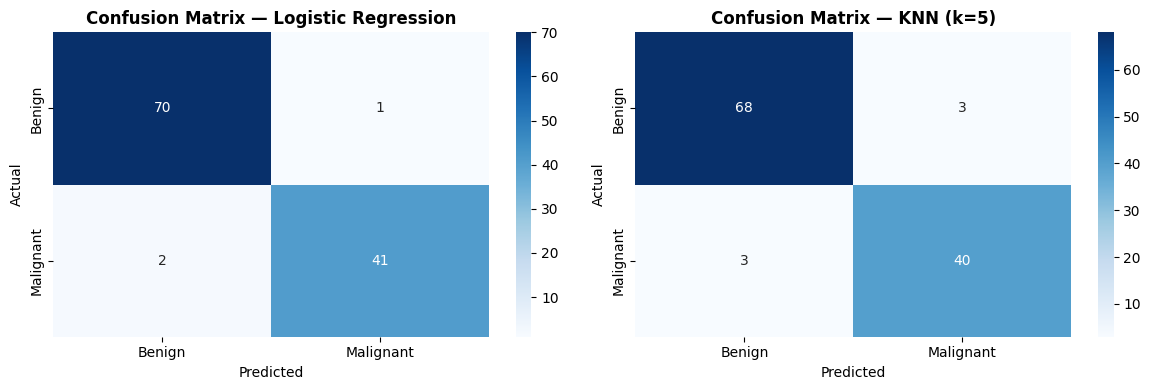

In [ ]:
# Side-by-side confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, y_pred, title in zip(
    axes, [y_pred_lr_bc, y_pred_knn_bc], ["Logistic Regression", "KNN (k=5)"]
):
    cm = confusion_matrix(y_test_bc, y_pred)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=["Benign", "Malignant"],
        yticklabels=["Benign", "Malignant"],
    )
    ax.set_title(f"Confusion Matrix — {title}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [ ]:
print("=== Classification Report: Logistic Regression ===")
print(
    classification_report(y_test_bc, y_pred_lr_bc, target_names=["Benign", "Malignant"])
)

print("=== Classification Report: KNN ===")
print(
    classification_report(
        y_test_bc, y_pred_knn_bc, target_names=["Benign", "Malignant"]
    )
)

=== Classification Report: Logistic Regression ===
              precision    recall  f1-score   support

      Benign       0.97      0.99      0.98        71
   Malignant       0.98      0.95      0.96        43

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114

=== Classification Report: KNN ===
              precision    recall  f1-score   support

      Benign       0.96      0.96      0.96        71
   Malignant       0.93      0.93      0.93        43

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



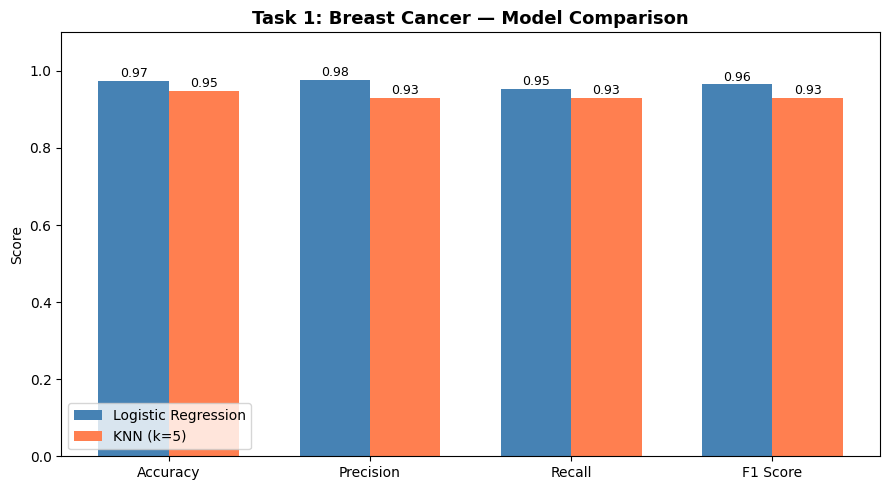

In [ ]:
# Bar chart comparison
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]
lr_scores = [
    accuracy_score(y_test_bc, y_pred_lr_bc),
    precision_score(y_test_bc, y_pred_lr_bc),
    recall_score(y_test_bc, y_pred_lr_bc),
    f1_score(y_test_bc, y_pred_lr_bc),
]
knn_scores = [
    accuracy_score(y_test_bc, y_pred_knn_bc),
    precision_score(y_test_bc, y_pred_knn_bc),
    recall_score(y_test_bc, y_pred_knn_bc),
    f1_score(y_test_bc, y_pred_knn_bc),
]

x = np.arange(len(metrics))
width = 0.35
fig, ax = plt.subplots(figsize=(9, 5))
bars1 = ax.bar(
    x - width / 2, lr_scores, width, label="Logistic Regression", color="steelblue"
)
bars2 = ax.bar(x + width / 2, knn_scores, width, label="KNN (k=5)", color="coral")
ax.set_ylim(0, 1.1)
ax.set_ylabel("Score")
ax.set_title("Task 1: Breast Cancer — Model Comparison", fontsize=13, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()
for bar in bars1:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{bar.get_height():.2f}",
        ha="center",
        fontsize=9,
    )
for bar in bars2:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{bar.get_height():.2f}",
        ha="center",
        fontsize=9,
    )
plt.tight_layout()
plt.show()

Task 2: Disease Diagnosis System


In [ ]:
# Step 1 — Load dataset
df_heart = pd.read_csv("heart.csv")
print("Shape:", df_heart.shape)
print("\nTarget distribution:")
print(df_heart["target"].value_counts())
df_heart.head()

Shape: (1025, 14)

Target distribution:
target
1    526
0    499
Name: count, dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [ ]:
# Use Age, Blood Pressure (trestbps), Cholesterol as features
features_heart = ["age", "trestbps", "chol"]
X_heart = df_heart[features_heart]
y_heart = df_heart["target"]

X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(
    X_heart, y_heart, test_size=0.2, random_state=42
)

scaler_h = StandardScaler()
X_train_h = scaler_h.fit_transform(X_train_h)
X_test_h = scaler_h.transform(X_test_h)

print(f"Training samples: {X_train_h.shape[0]}, Test samples: {X_test_h.shape[0]}")

Training samples: 820, Test samples: 205


In [ ]:
# Step 2 — Train model (Logistic Regression)
lr_heart = LogisticRegression(max_iter=500, random_state=42)
lr_heart.fit(X_train_h, y_train_h)
y_pred_heart = lr_heart.predict(X_test_h)

# Step 3 — Evaluate using Recall (critical for disease diagnosis)
recall_val = recall_score(y_test_h, y_pred_heart)
print("=== Task 2: Disease Diagnosis ===")
print(f"Accuracy  : {accuracy_score(y_test_h, y_pred_heart):.4f}")
print(
    f"Recall    : {recall_val:.4f}   ← KEY METRIC (catching all positive disease cases)"
)
print(f"Precision : {precision_score(y_test_h, y_pred_heart):.4f}")
print(f"F1 Score  : {f1_score(y_test_h, y_pred_heart):.4f}")

print("\n--- Why Recall matters here ---")
print(
    "In disease diagnosis, a False Negative (missing a sick patient) is more dangerous"
)
print("than a False Positive. So we prioritize RECALL over Precision.")

=== Task 2: Disease Diagnosis ===
Accuracy  : 0.6146
Recall    : 0.5922   ← KEY METRIC (catching all positive disease cases)
Precision : 0.6224
F1 Score  : 0.6070

--- Why Recall matters here ---
In disease diagnosis, a False Negative (missing a sick patient) is more dangerous
than a False Positive. So we prioritize RECALL over Precision.


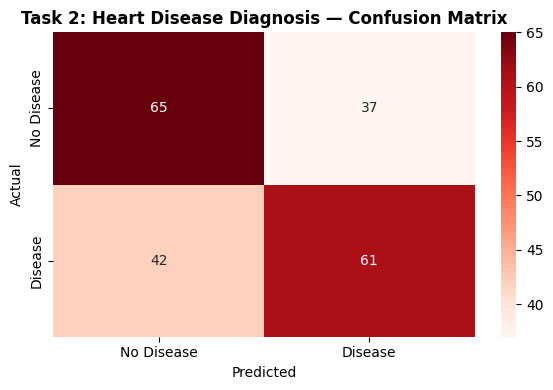

              precision    recall  f1-score   support

  No Disease       0.61      0.64      0.62       102
     Disease       0.62      0.59      0.61       103

    accuracy                           0.61       205
   macro avg       0.61      0.61      0.61       205
weighted avg       0.61      0.61      0.61       205



In [ ]:
# Confusion matrix
cm_heart = confusion_matrix(y_test_h, y_pred_heart)
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_heart,
    annot=True,
    fmt="d",
    cmap="Reds",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"],
)
plt.title("Task 2: Heart Disease Diagnosis — Confusion Matrix", fontweight="bold")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

print(
    classification_report(
        y_test_h, y_pred_heart, target_names=["No Disease", "Disease"]
    )
)

Task 3


In [ ]:
# Step 1 — Load dataset
df_churn = pd.read_csv("Customer-Churn.csv")
print("Shape:", df_churn.shape)
print("\nColumns:", df_churn.columns.tolist())
df_churn.head()

Shape: (7043, 21)

Columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
print("Churn distribution:")
print(df_churn["Churn"].value_counts())
print("\nMissing values:")
print(df_churn.isnull().sum())

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [ ]:
# Preprocess dataset — encode ALL categorical columns
df_churn_proc = df_churn.copy()

# Find ALL columns with object (string) dtype
cat_cols = df_churn_proc.select_dtypes(include=["object"]).columns.tolist()

# Remove 'Churn' from categorical columns if it's there (we'll handle it separately)
if "Churn" in cat_cols:
    cat_cols.remove("Churn")

# Encode all categorical columns
from sklearn.preprocessing import LabelEncoder

for col in cat_cols:
    print(f"Encoding column: {col}")
    df_churn_proc[col] = LabelEncoder().fit_transform(df_churn_proc[col])

# Target
df_churn_proc["Churn"] = (df_churn_proc["Churn"] == "Yes").astype(int)

# Verify all columns are now numeric
print("\nData types after encoding:")
print(df_churn_proc.dtypes)

X_churn = df_churn_proc.drop(columns=["Churn"])
y_churn = df_churn_proc["Churn"]

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_churn, y_churn, test_size=0.2, random_state=42
)

scaler_c = StandardScaler()
X_train_c = scaler_c.fit_transform(X_train_c)
X_test_c = scaler_c.transform(X_test_c)

print(f"Train: {X_train_c.shape[0]}, Test: {X_test_c.shape[0]}")

Encoding column: customerID
Encoding column: gender
Encoding column: Partner
Encoding column: Dependents
Encoding column: PhoneService
Encoding column: MultipleLines
Encoding column: InternetService
Encoding column: OnlineSecurity
Encoding column: OnlineBackup
Encoding column: DeviceProtection
Encoding column: TechSupport
Encoding column: StreamingTV
Encoding column: StreamingMovies
Encoding column: Contract
Encoding column: PaperlessBilling
Encoding column: PaymentMethod
Encoding column: TotalCharges

Data types after encoding:
customerID            int64
gender                int64
SeniorCitizen         int64
Partner               int64
Dependents            int64
tenure                int64
PhoneService          int64
MultipleLines         int64
InternetService       int64
OnlineSecurity        int64
OnlineBackup          int64
DeviceProtection      int64
TechSupport           int64
StreamingTV           int64
StreamingMovies       int64
Contract              int64
PaperlessBilling 

In [ ]:
# Train Logistic Regression
lr_churn = LogisticRegression(max_iter=1000, random_state=42)
lr_churn.fit(X_train_c, y_train_c)
y_pred_lr_c = lr_churn.predict(X_test_c)

# Train KNN
knn_churn = KNeighborsClassifier(n_neighbors=7)
knn_churn.fit(X_train_c, y_train_c)
y_pred_knn_c = knn_churn.predict(X_test_c)

print("Both models trained!")

Both models trained!


In [ ]:
# Compare models
evaluate_classifier("Logistic Regression — Churn", y_test_c, y_pred_lr_c)
evaluate_classifier("KNN (k=7) — Churn", y_test_c, y_pred_knn_c)


  Logistic Regression — Churn
Accuracy  : 0.8148
Precision : 0.6842
Recall    : 0.5576
F1 Score  : 0.6145

  KNN (k=7) — Churn
Accuracy  : 0.7715
Precision : 0.5770
Recall    : 0.5121
F1 Score  : 0.5426


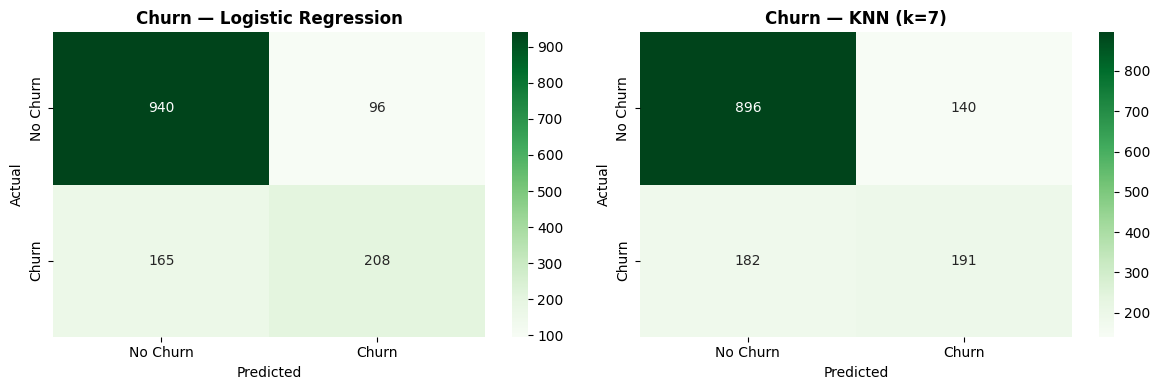

In [ ]:
# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, y_pred, title in zip(
    axes, [y_pred_lr_c, y_pred_knn_c], ["Logistic Regression", "KNN (k=7)"]
):
    cm = confusion_matrix(y_test_c, y_pred)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Greens",
        ax=ax,
        xticklabels=["No Churn", "Churn"],
        yticklabels=["No Churn", "Churn"],
    )
    ax.set_title(f"Churn — {title}", fontweight="bold")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

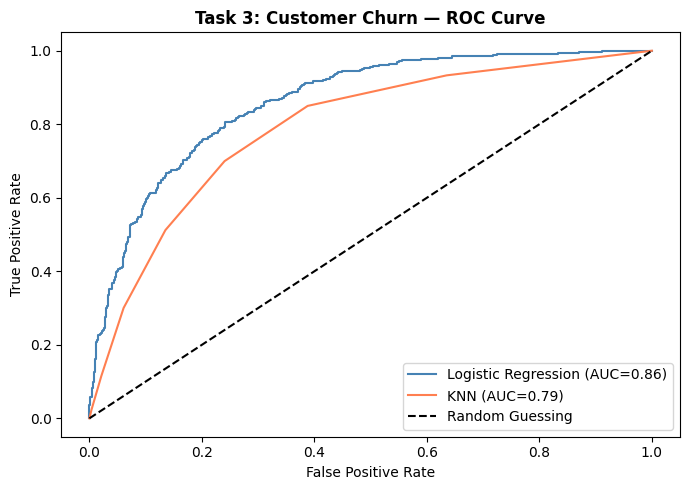

In [ ]:
# ROC curves for both models
lr_proba_c = lr_churn.predict_proba(X_test_c)[:, 1]
knn_proba_c = knn_churn.predict_proba(X_test_c)[:, 1]

fpr_lr, tpr_lr, _ = roc_curve(y_test_c, lr_proba_c)
fpr_knn, tpr_knn, _ = roc_curve(y_test_c, knn_proba_c)
auc_lr = roc_auc_score(y_test_c, lr_proba_c)
auc_knn = roc_auc_score(y_test_c, knn_proba_c)

plt.figure(figsize=(7, 5))
plt.plot(
    fpr_lr, tpr_lr, label=f"Logistic Regression (AUC={auc_lr:.2f})", color="steelblue"
)
plt.plot(fpr_knn, tpr_knn, label=f"KNN (AUC={auc_knn:.2f})", color="coral")
plt.plot([0, 1], [0, 1], "k--", label="Random Guessing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Task 3: Customer Churn — ROC Curve", fontweight="bold")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
print("=== Classification Report: Logistic Regression — Churn ===")
print(classification_report(y_test_c, y_pred_lr_c, target_names=["No Churn", "Churn"]))

print("=== Classification Report: KNN — Churn ===")
print(classification_report(y_test_c, y_pred_knn_c, target_names=["No Churn", "Churn"]))

=== Classification Report: Logistic Regression — Churn ===
              precision    recall  f1-score   support

    No Churn       0.85      0.91      0.88      1036
       Churn       0.68      0.56      0.61       373

    accuracy                           0.81      1409
   macro avg       0.77      0.73      0.75      1409
weighted avg       0.81      0.81      0.81      1409

=== Classification Report: KNN — Churn ===
              precision    recall  f1-score   support

    No Churn       0.83      0.86      0.85      1036
       Churn       0.58      0.51      0.54       373

    accuracy                           0.77      1409
   macro avg       0.70      0.69      0.70      1409
weighted avg       0.76      0.77      0.77      1409



Task 4


In [ ]:
# Load dataset
df_loan = pd.read_csv("Loan-status.csv")
print("Shape:", df_loan.shape)
print("\nLoan Status distribution:")
print(df_loan["Loan_Status"].value_counts())
df_loan.head()

Shape: (614, 13)

Loan Status distribution:
Loan_Status
Y    422
N    192
Name: count, dtype: int64


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [ ]:
# Step 1 — Handle categorical data
df_loan_proc = df_loan.copy()

# Drop missing values if any
df_loan_proc.dropna(inplace=True)

# Encode categorical columns
cat_cols_loan = ["Gender", "Married", "Education", "Self_Employed"]
for col in cat_cols_loan:
    df_loan_proc[col] = LabelEncoder().fit_transform(df_loan_proc[col])

# Target: Y=1 (Approved), N=0 (Rejected)
df_loan_proc["Loan_Status"] = (df_loan_proc["Loan_Status"] == "Y").astype(int)

X_loan = df_loan_proc.drop(columns=["Loan_Status"])
y_loan = df_loan_proc["Loan_Status"]

print("Features:", X_loan.columns.tolist())
print("Target distribution:")
print(y_loan.value_counts())

Features: ['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area']
Target distribution:
Loan_Status
1    332
0    148
Name: count, dtype: int64


In [ ]:
# Step 1 — Handle categorical data
df_loan_proc = df_loan.copy()

# Drop missing values if any
df_loan_proc.dropna(inplace=True)

# Drop ID columns if they exist
id_columns = ["Loan_ID", "Application_ID", "Customer_ID"]  # Common ID column names
for col in id_columns:
    if col in df_loan_proc.columns:
        df_loan_proc = df_loan_proc.drop(columns=[col])
        print(f"Dropped ID column: {col}")

# Find ALL categorical columns (object dtype)
cat_cols_loan = df_loan_proc.select_dtypes(include=["object"]).columns.tolist()

# Remove target from categorical columns if it's there
if "Loan_Status" in cat_cols_loan:
    cat_cols_loan.remove("Loan_Status")

print(f"Categorical columns to encode: {cat_cols_loan}")

# Encode all categorical columns
from sklearn.preprocessing import LabelEncoder

for col in cat_cols_loan:
    print(f"Encoding column: {col}")
    df_loan_proc[col] = LabelEncoder().fit_transform(df_loan_proc[col])

# Target: Y=1 (Approved), N=0 (Rejected)
df_loan_proc["Loan_Status"] = (df_loan_proc["Loan_Status"] == "Y").astype(int)

# Verify all columns are now numeric
print("\nData types after processing:")
print(df_loan_proc.dtypes)

X_loan = df_loan_proc.drop(columns=["Loan_Status"])
y_loan = df_loan_proc["Loan_Status"]

print("\nFeatures:", X_loan.columns.tolist())
print("Target distribution:")
print(y_loan.value_counts())

# Split & scale
X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(
    X_loan, y_loan, test_size=0.2, random_state=42
)

scaler_l = StandardScaler()
X_train_l = scaler_l.fit_transform(X_train_l)
X_test_l = scaler_l.transform(X_test_l)

# Step 2 — Train classifier
lr_loan = LogisticRegression(max_iter=500, random_state=42)
lr_loan.fit(X_train_l, y_train_l)
y_pred_loan = lr_loan.predict(X_test_l)

print("\nModel trained!")
print(f"Accuracy : {accuracy_score(y_test_l, y_pred_loan):.4f}")
print(f"Precision: {precision_score(y_test_l, y_pred_loan):.4f}")
print(f"Recall   : {recall_score(y_test_l, y_pred_loan):.4f}")
print(f"F1 Score : {f1_score(y_test_l, y_pred_loan):.4f}")

Dropped ID column: Loan_ID
Categorical columns to encode: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']
Encoding column: Gender
Encoding column: Married
Encoding column: Dependents
Encoding column: Education
Encoding column: Self_Employed
Encoding column: Property_Area

Data types after processing:
Gender                 int64
Married                int64
Dependents             int64
Education              int64
Self_Employed          int64
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area          int64
Loan_Status            int64
dtype: object

Features: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area']
Target distribution:
Loan_Status
1    332
0    148
Name: count, dtype: int64

Model trained!
Accuracy : 0.8229
Prec

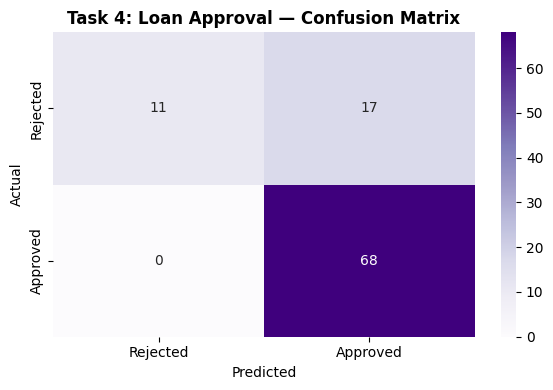

              precision    recall  f1-score   support

    Rejected       1.00      0.39      0.56        28
    Approved       0.80      1.00      0.89        68

    accuracy                           0.82        96
   macro avg       0.90      0.70      0.73        96
weighted avg       0.86      0.82      0.79        96



In [ ]:
# Step 3 — Evaluate using confusion matrix
cm_loan = confusion_matrix(y_test_l, y_pred_loan)
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_loan,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Rejected", "Approved"],
    yticklabels=["Rejected", "Approved"],
)
plt.title("Task 4: Loan Approval — Confusion Matrix", fontweight="bold")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

print(
    classification_report(y_test_l, y_pred_loan, target_names=["Rejected", "Approved"])
)

Task 5


In [ ]:
# Step 1 — Load dataset
df_iris = pd.read_csv("Iris.csv")
print("Shape:", df_iris.shape)
print("\nSpecies distribution:")
print(df_iris["Species"].value_counts())
df_iris.head()

Shape: (150, 6)

Species distribution:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:
# Step 2 — Split data
le_iris = LabelEncoder()
X_iris = df_iris.drop(columns=["Species"])
y_iris = le_iris.fit_transform(df_iris["Species"])

X_train_i, X_test_i, y_train_i, y_test_i = train_test_split(
    X_iris, y_iris, test_size=0.2, random_state=42
)
print(f"Train: {X_train_i.shape[0]}, Test: {X_test_i.shape[0]}")

Train: 120, Test: 30


In [ ]:
# Step 3 — Scale features
scaler_i = StandardScaler()
X_train_i = scaler_i.fit_transform(X_train_i)
X_test_i = scaler_i.transform(X_test_i)
print("Features scaled!")

Features scaled!


In [ ]:
# Step 4 — Train model
lr_iris = LogisticRegression(max_iter=500, random_state=42)
lr_iris.fit(X_train_i, y_train_i)
print("Logistic Regression trained!")

Logistic Regression trained!


In [ ]:
# Step 5 — Predict
y_pred_iris = lr_iris.predict(X_test_i)
predicted_labels = le_iris.inverse_transform(y_pred_iris)
actual_labels = le_iris.inverse_transform(y_test_i)
print("Sample Predictions:")
for actual, pred in zip(actual_labels[:10], predicted_labels[:10]):
    status = "✓" if actual == pred else "✗"
    print(f"  Actual: {actual:15s}  Predicted: {pred:15s}  {status}")

Sample Predictions:
  Actual: Iris-versicolor  Predicted: Iris-versicolor  ✓
  Actual: Iris-setosa      Predicted: Iris-setosa      ✓
  Actual: Iris-virginica   Predicted: Iris-virginica   ✓
  Actual: Iris-versicolor  Predicted: Iris-versicolor  ✓
  Actual: Iris-versicolor  Predicted: Iris-versicolor  ✓
  Actual: Iris-setosa      Predicted: Iris-setosa      ✓
  Actual: Iris-versicolor  Predicted: Iris-versicolor  ✓
  Actual: Iris-virginica   Predicted: Iris-virginica   ✓
  Actual: Iris-versicolor  Predicted: Iris-versicolor  ✓
  Actual: Iris-versicolor  Predicted: Iris-versicolor  ✓


=== Task 5: Iris Multi-Class Classification ===
Accuracy : 1.0000


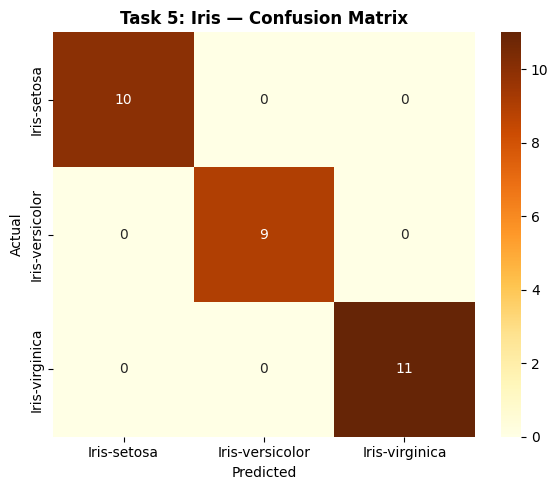

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00         9
 Iris-virginica       1.00      1.00      1.00        11

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



In [ ]:
# Step 6 — Evaluate
print("=== Task 5: Iris Multi-Class Classification ===")
print(f"Accuracy : {accuracy_score(y_test_i, y_pred_iris):.4f}")

cm_iris = confusion_matrix(y_test_i, y_pred_iris)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_iris,
    annot=True,
    fmt="d",
    cmap="YlOrBr",
    xticklabels=le_iris.classes_,
    yticklabels=le_iris.classes_,
)
plt.title("Task 5: Iris — Confusion Matrix", fontweight="bold")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

print(classification_report(y_test_i, y_pred_iris, target_names=le_iris.classes_))

PART 2


In [ ]:
def evaluate_regressor(name, y_true, y_pred):
    """Print all regression metrics for a model."""
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f'\n{"="*50}')
    print(f"  {name}")
    print(f'{"="*50}')
    print(f"MAE  : {mae:.4f}")
    print(f"MSE  : {mse:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"R²   : {r2:.4f}")
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}

In [ ]:
# Step 1 — Load dataset
df_house = pd.read_csv("housing.csv")
print("Shape:", df_house.shape)
df_house.head()

Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [40]:
df_house.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [ ]:
# Make a copy of the data
df_house_proc = df_house.copy()

# Identify categorical columns (object dtype)
cat_cols = df_house_proc.select_dtypes(include=["object"]).columns.tolist()
print(f"Categorical columns: {cat_cols}")

# Encode categorical columns
from sklearn.preprocessing import LabelEncoder

for col in cat_cols:
    if col != "median_house_value":  # Don't encode target
        print(f"Encoding column: {col}")
        df_house_proc[col] = LabelEncoder().fit_transform(df_house_proc[col])

# Separate features and target
X_house = df_house_proc.drop(columns=["median_house_value"])
y_house = df_house_proc["median_house_value"]

# Verify all features are now numeric
print("\nData types after encoding:")
print(X_house.dtypes)

# Split and scale
X_train_h2, X_test_h2, y_train_h2, y_test_h2 = train_test_split(
    X_house, y_house, test_size=0.2, random_state=42
)

scaler_h2 = StandardScaler()
X_train_h2 = scaler_h2.fit_transform(X_train_h2)
X_test_h2 = scaler_h2.transform(X_test_h2)

print(f"Train: {X_train_h2.shape[0]}, Test: {X_test_h2.shape[0]}")

Categorical columns: ['ocean_proximity']
Encoding column: ocean_proximity

Data types after encoding:
longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
ocean_proximity         int64
dtype: object
Train: 16512, Test: 4128


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Create imputer for missing values
imputer = SimpleImputer(
    strategy="mean"
)  # Use 'median' or 'most_frequent' as alternatives

# Fit imputer on training data and transform both train and test
X_train_h2_imputed = imputer.fit_transform(X_train_h2)
X_test_h2_imputed = imputer.transform(X_test_h2)

# Train model on imputed data
lr_house = LinearRegression()
lr_house.fit(X_train_h2_imputed, y_train_h2)
y_pred_lr_house = lr_house.predict(X_test_h2_imputed)

# Evaluate
lr_metrics = evaluate_regressor(
    "Linear Regression — Housing", y_test_h2, y_pred_lr_house
)


  Linear Regression — Housing
MAE  : 51847.2840
MSE  : 5055026565.8728
RMSE : 71098.7100
R²   : 0.6142


In [ ]:
# Step 3 — Try Decision Tree Regressor
dt_house = DecisionTreeRegressor(random_state=42, max_depth=8)
dt_house.fit(X_train_h2, y_train_h2)
y_pred_dt_house = dt_house.predict(X_test_h2)

dt_metrics = evaluate_regressor(
    "Decision Tree Regressor — Housing", y_test_h2, y_pred_dt_house
)


  Decision Tree Regressor — Housing
MAE  : 41314.5071
MSE  : 3751939201.4659
RMSE : 61253.0750
R²   : 0.7137


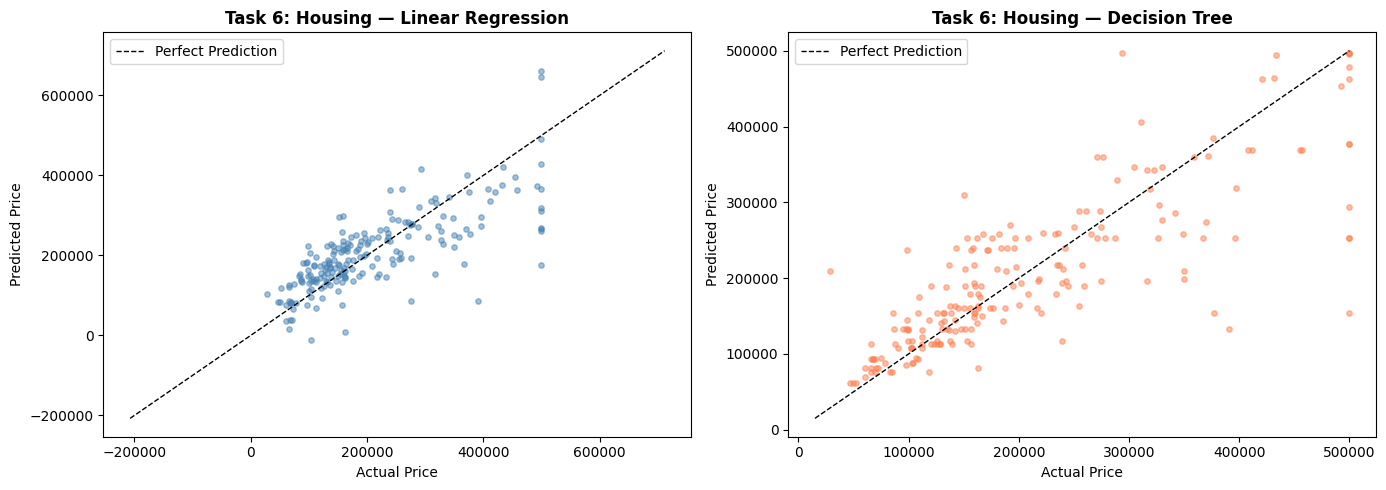

In [ ]:
# Actual vs Predicted plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sample = 200
idx = np.random.choice(len(y_test_h2), sample, replace=False)

for ax, y_pred, title, color in zip(
    axes,
    [y_pred_lr_house, y_pred_dt_house],
    ["Linear Regression", "Decision Tree"],
    ["steelblue", "coral"],
):
    y_true_arr = np.array(y_test_h2)
    ax.scatter(y_true_arr[idx], y_pred[idx], alpha=0.5, s=15, color=color)
    mn = min(y_true_arr.min(), y_pred.min())
    mx = max(y_true_arr.max(), y_pred.max())
    ax.plot([mn, mx], [mn, mx], "k--", lw=1, label="Perfect Prediction")
    ax.set_xlabel("Actual Price")
    ax.set_ylabel("Predicted Price")
    ax.set_title(f"Task 6: Housing — {title}", fontweight="bold")
    ax.legend()

plt.tight_layout()
plt.show()

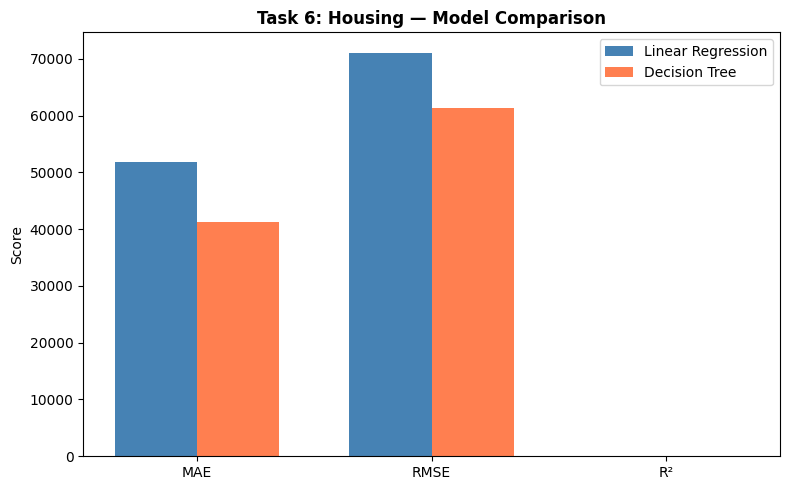

In [ ]:
# Metrics comparison bar chart
metrics_names = ["MAE", "RMSE", "R²"]
lr_vals = [lr_metrics["MAE"], lr_metrics["RMSE"], lr_metrics["R2"]]
dt_vals = [dt_metrics["MAE"], dt_metrics["RMSE"], dt_metrics["R2"]]

x = np.arange(len(metrics_names))
width = 0.35
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width / 2, lr_vals, width, label="Linear Regression", color="steelblue")
ax.bar(x + width / 2, dt_vals, width, label="Decision Tree", color="coral")
ax.set_ylabel("Score")
ax.set_title("Task 6: Housing — Model Comparison", fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(metrics_names)
ax.legend()
plt.tight_layout()
plt.show()

Task 7


In [ ]:
# Load dataset
df_car = pd.read_csv("CarPrice_Assignment.csv")
print("Shape:", df_car.shape)
print("\nColumns:", df_car.columns.tolist())
df_car.head()

Shape: (205, 26)

Columns: ['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [50]:
df_car.describe()

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


In [ ]:
# Use a combination of features
feature_cols = ["enginesize", "highwaympg"]
X_car = df_car[feature_cols]
y_car = df_car["price"]

X_train_car, X_test_car, y_train_car, y_test_car = train_test_split(
    X_car, y_car, test_size=0.2, random_state=42
)

scaler_car = StandardScaler()
X_train_car = scaler_car.fit_transform(X_train_car)
X_test_car = scaler_car.transform(X_test_car)

print(f"Train: {X_train_car.shape[0]}, Test: {X_test_car.shape[0]}")

Train: 164, Test: 41


In [ ]:
# Train Linear Regression
lr_car = LinearRegression()
lr_car.fit(X_train_car, y_train_car)
y_pred_car = lr_car.predict(X_test_car)

car_metrics = evaluate_regressor(
    "Linear Regression — Car Price", y_test_car, y_pred_car
)


  Linear Regression — Car Price
MAE  : 2925.0926
MSE  : 16997119.0366
RMSE : 4122.7562
R²   : 0.7847


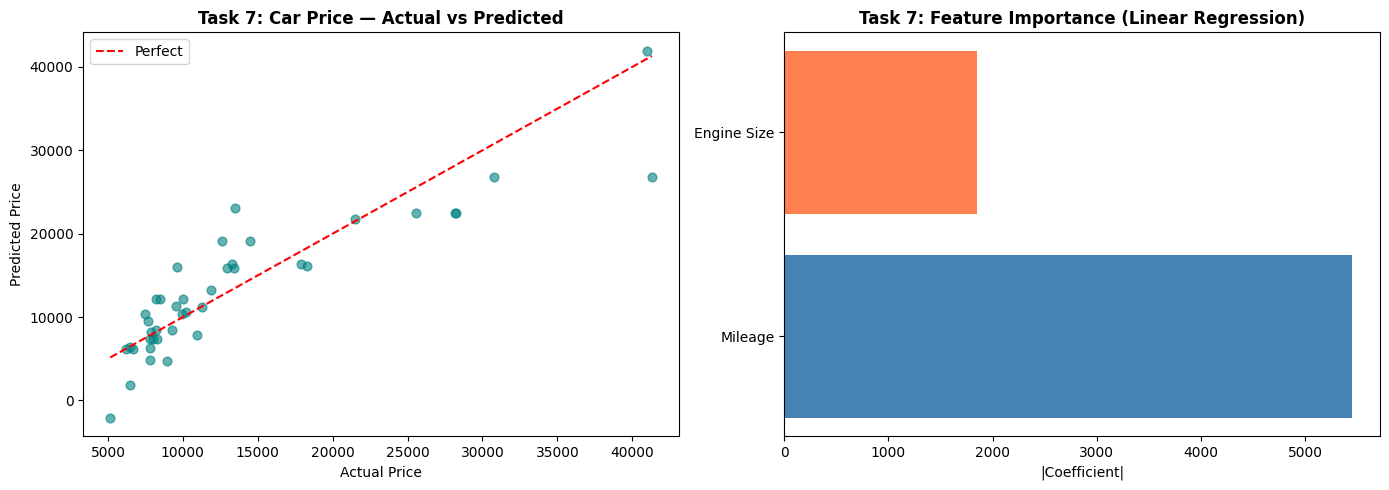


Linear Regression Coefficients:
  Mileage: 5446.03
  Engine Size: -1855.21
  Intercept: 13223.41


In [ ]:
# Visualize: Actual vs Predicted
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter plot
axes[0].scatter(y_test_car, y_pred_car, alpha=0.6, color="teal", s=40)
mn, mx = y_test_car.min(), y_test_car.max()
axes[0].plot([mn, mx], [mn, mx], "r--", label="Perfect")
axes[0].set_xlabel("Actual Price")
axes[0].set_ylabel("Predicted Price")
axes[0].set_title("Task 7: Car Price — Actual vs Predicted", fontweight="bold")
axes[0].legend()

# Feature importance (coefficients)
coefs = lr_car.coef_
features = ["Mileage", "Engine Size"]
axes[1].barh(features, np.abs(coefs), color=["steelblue", "coral"])
axes[1].set_xlabel("|Coefficient|")
axes[1].set_title("Task 7: Feature Importance (Linear Regression)", fontweight="bold")

plt.tight_layout()
plt.show()

print(f"\nLinear Regression Coefficients:")
for f, c in zip(features, coefs):
    print(f"  {f}: {c:.2f}")
print(f"  Intercept: {lr_car.intercept_:.2f}")

Task 8


In [ ]:
# Load dataset
df_ins = pd.read_csv("insurance.csv")
print("Shape:", df_ins.shape)
print("\nColumns:", df_ins.columns.tolist())
df_ins.head()

Shape: (1338, 7)

Columns: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


Missing values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Smoker distribution:
smoker
no     1064
yes     274
Name: count, dtype: int64


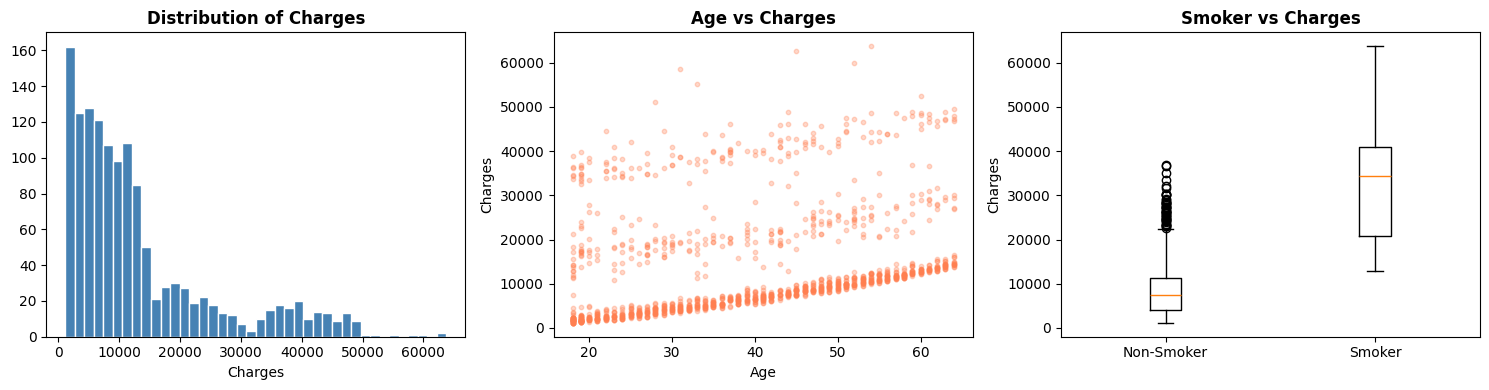

In [ ]:
print("Missing values:")
print(df_ins.isnull().sum())
print("\nSmoker distribution:")
print(df_ins["smoker"].value_counts())

# Visualize charges distribution
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(df_ins["charges"], bins=40, color="steelblue", edgecolor="white")
axes[0].set_title("Distribution of Charges", fontweight="bold")
axes[0].set_xlabel("Charges")

axes[1].scatter(df_ins["age"], df_ins["charges"], alpha=0.3, color="coral", s=10)
axes[1].set_title("Age vs Charges", fontweight="bold")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Charges")

smoker_yes = df_ins[df_ins["smoker"] == "yes"]["charges"]
smoker_no = df_ins[df_ins["smoker"] == "no"]["charges"]
axes[2].boxplot([smoker_no, smoker_yes], labels=["Non-Smoker", "Smoker"])
axes[2].set_title("Smoker vs Charges", fontweight="bold")
axes[2].set_ylabel("Charges")

plt.tight_layout()
plt.show()

In [ ]:
# Step 1 — Encode categorical variables
df_ins_proc = df_ins.copy()

# Encode 'sex', 'smoker', 'region'
df_ins_proc["sex"] = LabelEncoder().fit_transform(df_ins_proc["sex"])
df_ins_proc["smoker"] = LabelEncoder().fit_transform(df_ins_proc["smoker"])
df_ins_proc["region"] = LabelEncoder().fit_transform(df_ins_proc["region"])

print("After encoding:")
df_ins_proc.head()

After encoding:


,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,1,3,16884.92400
1,18,1,33.770,1,0,2,1725.55230
2,28,1,33.000,3,0,2,4449.46200
3,33,1,22.705,0,0,1,21984.47061
4,32,1,28.880,0,0,1,3866.85520


In [ ]:
# Use Age, BMI, Smoking Status + all features
X_ins = df_ins_proc.drop(columns=["charges"])
y_ins = df_ins_proc["charges"]

X_train_ins, X_test_ins, y_train_ins, y_test_ins = train_test_split(
    X_ins, y_ins, test_size=0.2, random_state=42
)

scaler_ins = StandardScaler()
X_train_ins = scaler_ins.fit_transform(X_train_ins)
X_test_ins = scaler_ins.transform(X_test_ins)

print(f"Train: {X_train_ins.shape[0]}, Test: {X_test_ins.shape[0]}")

Train: 1070, Test: 268


In [ ]:
# Step 2 — Train model (Linear Regression)
lr_ins = LinearRegression()
lr_ins.fit(X_train_ins, y_train_ins)
y_pred_ins = lr_ins.predict(X_test_ins)

ins_metrics = evaluate_regressor(
    "Linear Regression — Insurance", y_test_ins, y_pred_ins
)


  Linear Regression — Insurance
MAE  : 4186.5089
MSE  : 33635210.4312
RMSE : 5799.5871
R²   : 0.7833


In [ ]:
# Step 3 — Interpret results
feature_names = X_ins.columns.tolist()
coefficients = lr_ins.coef_

coef_df = pd.DataFrame({"Feature": feature_names, "Coefficient": coefficients})
coef_df["Abs_Coef"] = np.abs(coef_df["Coefficient"])
coef_df = coef_df.sort_values("Abs_Coef", ascending=True)

print("=== Model Interpretation: Feature Coefficients ===")
print(coef_df[["Feature", "Coefficient"]].to_string(index=False))
print(f"\nIntercept: {lr_ins.intercept_:.2f}")

=== Model Interpretation: Feature Coefficients ===
 Feature  Coefficient
     sex    -9.392954
  region  -302.387980
children   516.662566
     bmi  2028.308579
     age  3616.108652
  smoker  9557.143383

Intercept: 13346.09


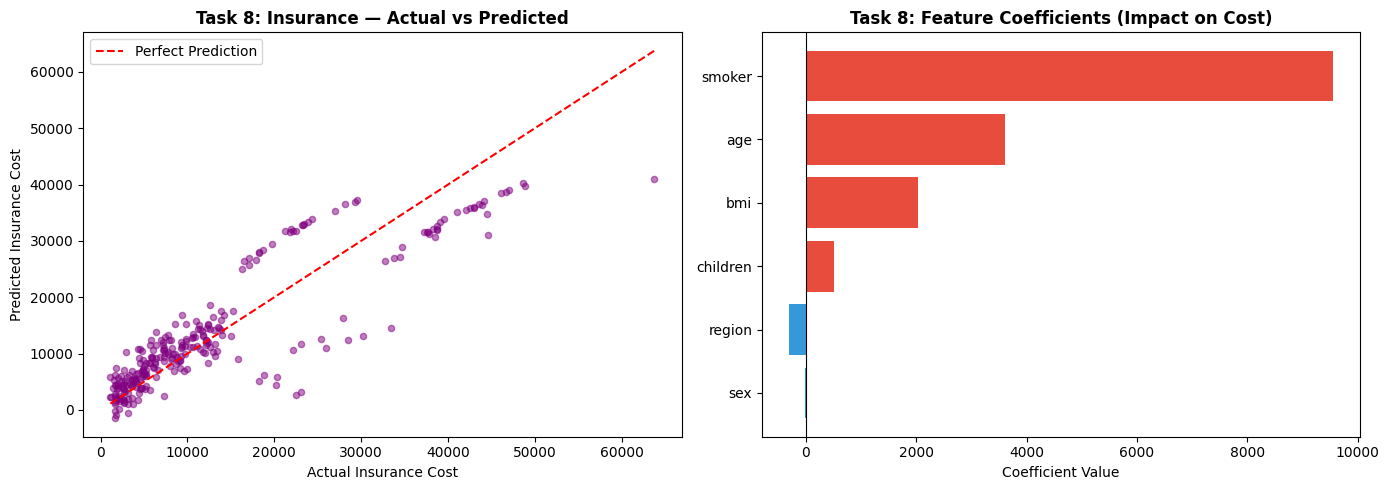


=== Interpretation Summary ===
• smoker: Largest positive coefficient → Smoking significantly increases insurance cost
• age   : Positive coefficient → Older patients pay more
• bmi   : Positive coefficient → Higher BMI increases cost
• sex   : Smallest effect on cost


In [ ]:
# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted
axes[0].scatter(y_test_ins, y_pred_ins, alpha=0.5, color="purple", s=20)
mn, mx = y_test_ins.min(), y_test_ins.max()
axes[0].plot([mn, mx], [mn, mx], "r--", label="Perfect Prediction")
axes[0].set_xlabel("Actual Insurance Cost")
axes[0].set_ylabel("Predicted Insurance Cost")
axes[0].set_title("Task 8: Insurance — Actual vs Predicted", fontweight="bold")
axes[0].legend()

# Feature importance
colors = ["#e74c3c" if c > 0 else "#3498db" for c in coef_df["Coefficient"]]
axes[1].barh(coef_df["Feature"], coef_df["Coefficient"], color=colors)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Coefficient Value")
axes[1].set_title("Task 8: Feature Coefficients (Impact on Cost)", fontweight="bold")

plt.tight_layout()
plt.show()

print("\n=== Interpretation Summary ===")
print(
    "• smoker: Largest positive coefficient → Smoking significantly increases insurance cost"
)
print("• age   : Positive coefficient → Older patients pay more")
print("• bmi   : Positive coefficient → Higher BMI increases cost")
print("• sex   : Smallest effect on cost")